# Auditoría de rumores y fichajes confirmados

## Librerías

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from pathlib import Path
from math import pi
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler
import ipywidgets as widgets
from IPython.display import display, clear_output
import warnings
warnings.filterwarnings('ignore')

## Carga de datos y variables

In [4]:
# Rutas de archivos
RUTA_DATA = Path.cwd().parent.parent / 'data'
RUTA_MERCADO = RUTA_DATA / 'scout' / 'mercado.csv'
RUTA_FILIAL = RUTA_DATA / 'laspalmasb' / 'Las Palmas Atletico 25_26.xlsx'
RUTA_UDLP = RUTA_DATA / 'udlaspalmas' / 'Individual Las Palmas 2526.xlsx'

# Diccionario de traducción
DICCIONARIO_COLUMNAS = {
    'Player': 'Jugador', 'Jugador': 'Jugador',
    'Team': 'Equipo', 'Equipo': 'Equipo',
    'Position': 'Posicion', 'Posición específica': 'Posicion', 'Posicion': 'Posicion',
    'Age': 'Edad', 'Edad': 'Edad',
    'Foot': 'Pie', 'Pie': 'Pie',
    'Market value': 'Valor_MEur', 'Valor de mercado (Transfermarkt)': 'Valor_MEur', 'Valor_MEur': 'Valor_MEur',
    'Contract expires': 'Fin_Contrato', 'Vencimiento contrato': 'Fin_Contrato', 'Fin_Contrato': 'Fin_Contrato',
    'Minutes played': 'Minutos', 'Minutos jugados': 'Minutos', 'Minutos': 'Minutos',
    'Team within selected timeframe': 'Equipo_Actual', 'Equipo durante el período seleccionado': 'Equipo_Actual',

    # Métricas de jugadores de campo
    'Defensive duels per 90': 'Duelos_Defensivos_P90', 'Duelos defensivos/90': 'Duelos_Defensivos_P90',
    'Interceptions per 90': 'Interceptaciones_P90', 'Interceptaciones/90': 'Interceptaciones_P90',
    'Aerial duels per 90': 'Duelos_Aereos_P90', 'Duelos aéreos en los 90': 'Duelos_Aereos_P90',
    'Passes to final third per 90': 'Pases_Ultimo_Tercio_P90', 'Pases en el último tercio/90': 'Pases_Ultimo_Tercio_P90',
    'Progressive runs per 90': 'Conducciones_Progresivas_P90', 'Carreras en progresión/90': 'Conducciones_Progresivas_P90',
    'Key passes per 90': 'Pases_Clave_P90', 'Jugadas claves/90': 'Pases_Clave_P90',
    'Dribbles per 90': 'Regates_P90', 'Regates/90': 'Regates_P90',
    'Crosses per 90': 'Centros_P90', 'Centros/90': 'Centros_P90',
    'xA per 90': 'xA_P90', 'xA/90': 'xA_P90',
    'Goals per 90': 'Goles_P90', 'Goles/90': 'Goles_P90',
    'xG per 90': 'xG_P90', 'xG/90': 'xG_P90',
    'Touches in box per 90': 'Toques_Area_P90', 'Toques en el área de penalti/90': 'Toques_Area_P90',
    'Shots per 90': 'Remates_P90', 'Remates/90': 'Remates_P90',
    'Offensive duels per 90': 'Duelos_Ofensivos_P90', 'Duelos atacantes/90': 'Duelos_Ofensivos_P90',

    # Métricas de portero
    'Short / medium passes per 90': 'Pases_Corto_Medio_P90',
    'Forward passes per 90': 'Pases_Adelante_P90',
    'Long passes per 90': 'Pases_Largos_P90',
    'Conceded goals per 90': 'Goles_Encajados_P90',
    'Prevented goals per 90': 'Goles_Evitados_P90',
}

# Familias de posición
GRUPOS_POSICION = [
    ('GK', 'Portero'),
    ('LB|RB|LWB|RWB|LI|RI', 'Lateral'),
    ('CB', 'Defensa central'),
    ('DMF|CMF', 'Mediocentro'),
    ('AMF', 'Mediocentro ofensivo'),
    ('LW|RW', 'Extremo'),
    ('CF', 'Delantero centro'),
]

# Perfiles ideales de Las Palmas por posición
PERFILES_OBJETIVO = {
    'Portero': {
        'metricas': ['Pases_Corto_Medio_P90', 'Pases_Adelante_P90', 'Pases_Largos_P90', 'Goles_Encajados_P90', 'Goles_Evitados_P90'],
        'pesos': [0.15, 0.15, 0.15, 0.25, 0.30]
    },
    'Defensa central': {
        'metricas': ['Duelos_Defensivos_P90', 'Interceptaciones_P90', 'Duelos_Aereos_P90', 'Pases_Ultimo_Tercio_P90', 'Conducciones_Progresivas_P90'],
        'pesos': [0.30, 0.25, 0.20, 0.15, 0.10]
    },
    'Lateral': {
        'metricas': ['Conducciones_Progresivas_P90', 'Centros_P90', 'Pases_Ultimo_Tercio_P90', 'Duelos_Defensivos_P90', 'Interceptaciones_P90'],
        'pesos': [0.25, 0.20, 0.25, 0.15, 0.15]
    },
    'Mediocentro': {
        'metricas': ['Pases_Ultimo_Tercio_P90', 'Pases_Adelante_P90', 'Duelos_Defensivos_P90', 'Interceptaciones_P90', 'Conducciones_Progresivas_P90'],
        'pesos': [0.30, 0.20, 0.25, 0.15, 0.10]
    },
    'Mediocentro ofensivo': {
        'metricas': ['Pases_Ultimo_Tercio_P90', 'Pases_Clave_P90', 'Conducciones_Progresivas_P90', 'Regates_P90', 'xA_P90'],
        'pesos': [0.30, 0.25, 0.20, 0.15, 0.10]
    },
    'Extremo': {
        'metricas': ['Regates_P90', 'Conducciones_Progresivas_P90', 'Centros_P90', 'xA_P90', 'Toques_Area_P90'],
        'pesos': [0.30, 0.25, 0.15, 0.15, 0.15]
    },
    'Delantero centro': {
        'metricas': ['Goles_P90', 'xG_P90', 'Toques_Area_P90', 'Remates_P90', 'Duelos_Ofensivos_P90'],
        'pesos': [0.35, 0.25, 0.20, 0.10, 0.10]
    }
}

In [ ]:
def normalizar_pie(pie):
    """Unifica la lateralidad sin importar si el Excel viene en inglés o español"""
    pie_str = str(pie).lower().strip()
    if pie_str in ['right', 'derecho']: return 'diestro'
    if pie_str in ['left', 'izquierdo']: return 'zurdo'
    if pie_str in ['both', 'ambidiestro']: return 'ambidiestro'
    return 'desconocido'

# Mercado global
df_mercado = pd.read_csv(RUTA_MERCADO).fillna(0)
df_mercado = df_mercado.rename(columns=DICCIONARIO_COLUMNAS)
df_mercado = df_mercado.loc[:, ~df_mercado.columns.duplicated()] 
if 'Carpeta_Origen' not in df_mercado.columns:
    df_mercado['Carpeta_Origen'] = 'mercado'

# Filial, homogeneizado al mismo esquema que el mercado.
df_filial = pd.read_excel(RUTA_FILIAL).fillna(0)
df_filial = df_filial.rename(columns=DICCIONARIO_COLUMNAS)
df_filial = df_filial.loc[:, ~df_filial.columns.duplicated()]  
df_filial['Carpeta_Origen'] = 'filial'
if 'Equipo' not in df_filial.columns:
    df_filial['Equipo'] = 'Las Palmas Atlético'
for columna in ['Valor_MEur', 'Fin_Contrato']:
    if columna not in df_filial.columns:
        df_filial[columna] = np.nan

# Normalizar pie en ambos universos
for df in (df_mercado, df_filial):
    if 'Pie' in df.columns:
        df['Pie_Normalizado'] = df['Pie'].apply(normalizar_pie)
    else:
        df['Pie_Normalizado'] = 'desconocido'

# Universo unificado: mercado exterior + cantera
COLUMNAS_COMUNES = [c for c in df_mercado.columns if c in df_filial.columns]
df_universo = pd.concat(
    [df_mercado[COLUMNAS_COMUNES], df_filial[COLUMNAS_COMUNES]],
    ignore_index=True
)

# Plantilla 25/26 de Las Palmas, para las comparaciones directas de la Función 2
df_udlp = pd.read_excel(RUTA_UDLP).fillna(0)
df_udlp = df_udlp.rename(columns=DICCIONARIO_COLUMNAS)
df_udlp = df_udlp.loc[:, ~df_udlp.columns.duplicated()]  
df_udlp['Pie_Normalizado'] = df_udlp['Pie'].apply(normalizar_pie) if 'Pie' in df_udlp.columns else 'desconocido'

print(f"Universo unificado: {len(df_universo)} jugadores "
      f"({len(df_mercado)} de mercado + {len(df_filial)} de la cantera).")

Universo unificado: 7323 jugadores (7297 de mercado + 26 de la cantera).


## Funciones de similitud

In [ ]:
def obtener_patron_posicion(posicion_codigo, grupos=GRUPOS_POSICION):
    """Traduce un código de posición específico de Wyscout a su familia de posición."""
    for patron, _nombre in grupos:
        if re.search(patron, str(posicion_codigo), flags=re.IGNORECASE):
            return patron
    return str(posicion_codigo)


def buscar_por_nombre(nombre, universo=None):
    """Primer intento de búsqueda: coincidencia parcial por nombre de jugador."""
    if universo is None:
        universo = df_universo
    return universo[universo['Jugador'].str.contains(nombre, case=False, na=False)]


def buscar_por_filtros(universo=None, liga=None, club=None, posicion=None):
    """
    Segundo intento: filtrar por liga/origen, club y familia de posición.
    Pensado para usarse cuando la búsqueda por nombre no da resultado.
    """
    if universo is None:
        universo = df_universo
    resultado = universo.copy()
    if liga and liga != 'Todas':
        resultado = resultado[resultado['Carpeta_Origen'] == liga]
    if club and club != 'Todos':
        resultado = resultado[resultado['Equipo'] == club]
    if posicion and posicion != 'Todas':
        # 'posicion' aquí es el nombre de familia elegido en el desplegable (ej. 'Defensa central'),
        # no un código Wyscout, así que se busca el patrón por nombre en vez de traducirlo de nuevo.
        patron = next((p for p, nombre in GRUPOS_POSICION if nombre == posicion), posicion)
        resultado = resultado[resultado['Posicion'].str.contains(patron, case=False, na=False, regex=True)]
    return resultado


def obtener_opciones_filtro(universo=None):
    if universo is None:
        universo = df_universo
    ligas = ['Todas'] + sorted(universo['Carpeta_Origen'].dropna().unique().tolist())
    clubes = ['Todos'] + sorted(universo['Equipo'].dropna().unique().tolist())
    posiciones = ['Todas'] + [nombre for _, nombre in GRUPOS_POSICION]
    return ligas, clubes, posiciones

In [ ]:
# Solo se usan si la búsqueda por nombre no encuentra nada
ligas_disponibles, clubes_disponibles, posiciones_disponibles = obtener_opciones_filtro()

texto_nombre = widgets.Text(description='Nombre:', placeholder="Ej. Mika Mármol")
desplegable_liga = widgets.Dropdown(options=ligas_disponibles, description='Liga:')
desplegable_club = widgets.Dropdown(options=clubes_disponibles, description='Club:')
desplegable_posicion = widgets.Dropdown(options=posiciones_disponibles, description='Posición:')
boton_buscar = widgets.Button(description='Buscar', button_style='primary')
salida_busqueda = widgets.Output()

resultado_busqueda = pd.DataFrame()

def al_pulsar_buscar(_boton):
    global resultado_busqueda
    with salida_busqueda:
        clear_output()
        encontrado = pd.DataFrame()
        if texto_nombre.value.strip():
            encontrado = buscar_por_nombre(texto_nombre.value.strip())
        if encontrado.empty:
            if texto_nombre.value.strip():
                print(f"No se ha encontrado a '{texto_nombre.value}' por nombre. "
                      f"Aplicando filtros de Liga / Club / Posición...")
            encontrado = buscar_por_filtros(
                liga=desplegable_liga.value,
                club=desplegable_club.value,
                posicion=desplegable_posicion.value
            )
        resultado_busqueda = encontrado
        if resultado_busqueda.empty:
            print("Sin resultados. Prueba a relajar los filtros.")
        else:
            print(f"{len(resultado_busqueda)} jugador(es) encontrados:")
            display(resultado_busqueda[['Jugador', 'Equipo', 'Posicion', 'Edad', 'Carpeta_Origen']].head(15))

boton_buscar.on_click(al_pulsar_buscar)

display(widgets.HBox([texto_nombre]))
display(widgets.HBox([desplegable_liga, desplegable_club, desplegable_posicion]))
display(boton_buscar, salida_busqueda)

## Visualizaciones

In [ ]:
def calcular_ajuste_estilo(jugador_serie, perfiles=None, universo_referencia=None):
    """
    Calcula el Score_Fit de un jugador respecto al perfil ideal de Las Palmas
    para su familia de posición, normalizando sobre el universo de referencia.
    """
    if perfiles is None:
        perfiles = PERFILES_OBJETIVO
    if universo_referencia is None:
        universo_referencia = df_universo

    posicion_principal = str(jugador_serie['Posicion']).split(',')[0].strip()
    patron_posicion = obtener_patron_posicion(posicion_principal)
    nombre_perfil = next((nombre for patron, nombre in GRUPOS_POSICION if patron == patron_posicion), None)

    if nombre_perfil is None or nombre_perfil not in perfiles:
        print(f"No hay un perfil de estilo definido para la posición '{posicion_principal}'.")
        return None

    perfil = perfiles[nombre_perfil]
    metricas = [m for m in perfil['metricas'] if m in universo_referencia.columns]
    pesos = perfil['pesos'][:len(metricas)]

    if not metricas:
        print(f"Ninguna métrica del perfil '{nombre_perfil}' está disponible en el universo.")
        return None

    grupo_referencia = universo_referencia[
        universo_referencia['Posicion'].str.contains(patron_posicion, case=False, na=False, regex=True)
    ]
    if grupo_referencia.empty:
        print("No hay suficiente universo de referencia para normalizar esta posición.")
        return None

    valores_norm = {}
    for metrica in metricas:
        minimo = grupo_referencia[metrica].min()
        maximo = grupo_referencia[metrica].max()
        rango = maximo - minimo
        valor = jugador_serie.get(metrica, 0)
        valores_norm[metrica] = 0.5 if rango == 0 else (valor - minimo) / rango

    score = sum(valores_norm[m] * p for m, p in zip(metricas, pesos)) * 100
    return {
        'nombre_perfil': nombre_perfil,
        'metricas': metricas,
        'valores_norm': valores_norm,
        'score': round(score, 2)
    }


def graficar_radar_estilo(jugador_serie, ajuste):
    metricas = ajuste['metricas']
    valores = [ajuste['valores_norm'][m] for m in metricas]
    n = len(metricas)
    angulos = [i / float(n) * 2 * pi for i in range(n)] + [0]
    valores = valores + valores[:1]

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True), facecolor='#F8FAFC')
    ax.set_facecolor('#F8FAFC')
    plt.xticks(angulos[:-1], [m.replace('_P90', '').replace('_', ' ') for m in metricas], size=10)
    ax.set_rlabel_position(30)
    plt.ylim(0, 1.0)
    ax.plot(angulos, valores, linewidth=2.5, color='#005BBB')
    ax.fill(angulos, valores, color='#005BBB', alpha=0.25)
    plt.title(f"Ajuste al estilo: {jugador_serie['Jugador']} ({ajuste['score']}%)",
              fontweight='bold', color='#003057', pad=20)
    plt.tight_layout()
    plt.show()

Mika Mármol (Las Palmas) -> Score_Fit: 31.44%


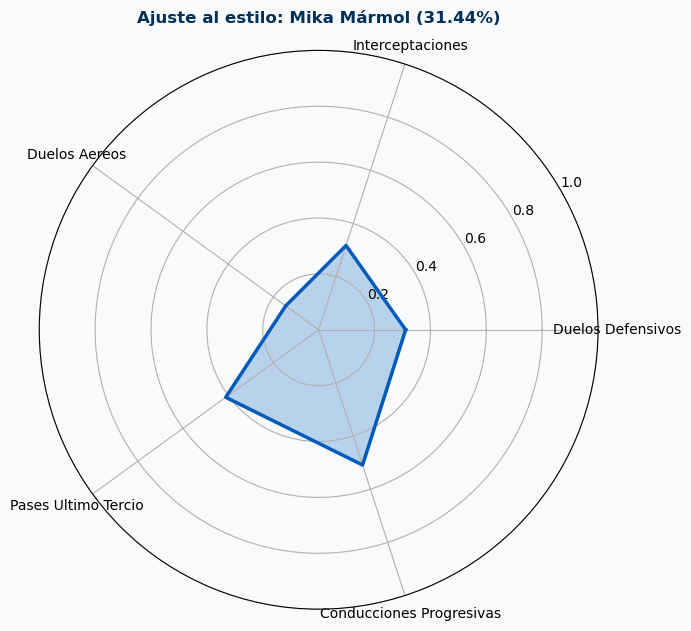

In [12]:
if not resultado_busqueda.empty:
    jugador_objetivo = resultado_busqueda.iloc[0]
    ajuste = calcular_ajuste_estilo(jugador_objetivo)
    if ajuste:
        print(f"{jugador_objetivo['Jugador']} ({jugador_objetivo['Equipo']}) -> Score_Fit: {ajuste['score']}%")
        graficar_radar_estilo(jugador_objetivo, ajuste)
else:
    print("Busca primero un jugador en la sección de Motor de búsqueda.")

## Visualización 2

In [ ]:
def comparar_con_jugador_club(candidato_serie, nombre_jugador_club, df_equipo=None, metricas=None):
    """
    Compara estadísticamente a un candidato con un jugador
    concreto de la plantilla de Las Palmas, para ver qué aportaría de distinto
    respecto a lo que ya se busca en el estilo del equipo.
    """
    if df_equipo is None:
        df_equipo = df_udlp

    objetivo = df_equipo[df_equipo['Jugador'].str.contains(nombre_jugador_club, case=False, na=False)]
    if objetivo.empty:
        print(f"Error: no se ha encontrado a '{nombre_jugador_club}' en la plantilla de la UDLP.")
        return None
    objetivo = objetivo.iloc[0]

    if metricas is None:
        posicion_principal = str(candidato_serie['Posicion']).split(',')[0].strip()
        patron_posicion = obtener_patron_posicion(posicion_principal)
        nombre_perfil = next((n for p, n in GRUPOS_POSICION if p == patron_posicion), None)
        metricas = PERFILES_OBJETIVO.get(nombre_perfil, {}).get('metricas', [])

    metricas_validas = [m for m in metricas if m in candidato_serie.index and m in objetivo.index]
    if not metricas_validas:
        print("No hay métricas comparables entre ambos jugadores.")
        return None

    df_comp = pd.DataFrame([
        {m: float(objetivo.get(m, 0)) for m in metricas_validas},
        {m: float(candidato_serie.get(m, 0)) for m in metricas_validas},
    ], index=[objetivo['Jugador'], candidato_serie['Jugador']])

    scaler = StandardScaler()
    valores_norm = scaler.fit_transform(df_comp)
    similitud = cosine_similarity(valores_norm[[0]], valores_norm[[1]])[0][0] * 100

    diferencia = df_comp.loc[candidato_serie['Jugador']] - df_comp.loc[objetivo['Jugador']]

    return {
        'jugador_club': objetivo['Jugador'],
        'candidato': candidato_serie['Jugador'],
        'similitud': round(similitud, 2),
        'diferencia': diferencia,
        'metricas': metricas_validas
    }


def graficar_diferencial(comparacion):
    diferencia = comparacion['diferencia']
    colores = ['#2E7D32' if v >= 0 else '#B00020' for v in diferencia.values]
    plt.figure(figsize=(9, 5), facecolor='#F8FAFC')
    plt.barh([m.replace('_P90', '').replace('_', ' ') for m in diferencia.index],
              diferencia.values, color=colores)
    plt.axvline(0, color='gray', linewidth=1)
    plt.title(
        f"{comparacion['candidato']} vs {comparacion['jugador_club']}",
        fontweight='bold', color='#003057'
    )
    plt.xlabel('Diferencia (candidato − jugador de la plantilla)')
    plt.tight_layout()
    plt.show()

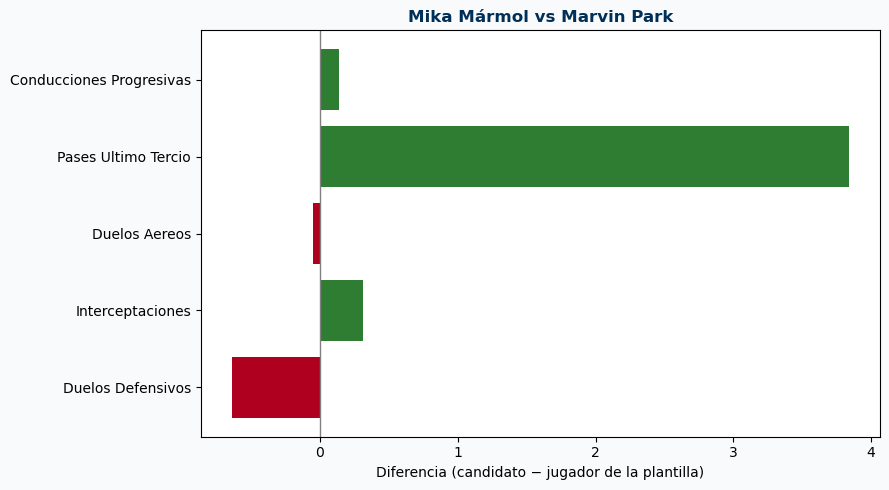

In [11]:
# Escribe aquí el jugador de la plantilla 25/26 con el que quieras comparar al candidato encontrado arriba
JUGADOR_CLUB_COMPARAR = "Marvin"

if not resultado_busqueda.empty:
    candidato = resultado_busqueda.iloc[0]
    comparacion = comparar_con_jugador_club(candidato, JUGADOR_CLUB_COMPARAR)
    if comparacion:
        graficar_diferencial(comparacion)
else:
    print("Busca primero un jugador en la sección de Motor de búsqueda.")

## Resumen

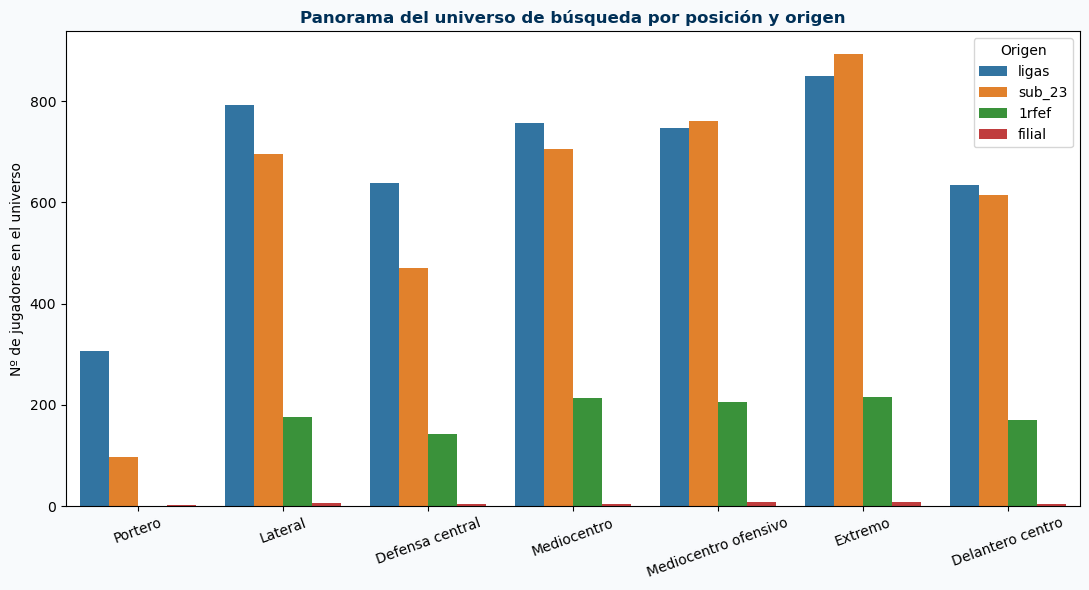

In [ ]:
def graficar_panorama_posiciones(universo=None):
    """
    Muestra cuántos jugadores hay disponibles en el universo
    por cada familia de posición, para ver cómo se está moviendo la UD:
    dónde hay más profundidad externa y dónde depende más del filial.
    """
    if universo is None:
        universo = df_universo

    filas = []
    for patron, nombre in GRUPOS_POSICION:
        mask = universo['Posicion'].str.contains(patron, case=False, na=False, regex=True)
        for origen in universo['Carpeta_Origen'].dropna().unique():
            filas.append({
                'Posicion': nombre,
                'Origen': origen,
                'Jugadores': int((mask & (universo['Carpeta_Origen'] == origen)).sum())
            })
    df_panorama = pd.DataFrame(filas)

    plt.figure(figsize=(11, 6), facecolor='#F8FAFC')
    sns.barplot(data=df_panorama, x='Posicion', y='Jugadores', hue='Origen')
    plt.title('Panorama del universo de búsqueda por posición y origen',
              fontweight='bold', color='#003057')
    plt.xlabel('')
    plt.ylabel('Nº de jugadores en el universo')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
    return df_panorama

df_panorama_posiciones = graficar_panorama_posiciones()